# DS605: Fundamentals of Machine Learning
## Lab Assignment 8 — Decision Trees and Support Vector Machines

**Dataset:** UCI Banknote Authentication (1,372 samples, four features, two classes).

This notebook implements a Decision Tree and a linear soft-margin SVM from scratch, compares them with Scikit-learn, explores nonlinear SVM kernels, and evaluates all required models on the original four-feature dataset.

**Requirement followed:** two features (`variance`, `skewness`) are used for 2D boundary plots; all four features are used for final evaluation. The manual algorithms use NumPy/Pandas, not Scikit-learn.

## 1. Imports and dataset

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
names = ["variance", "skewness", "curtosis", "entropy", "class"]
data = pd.read_csv(url, header=None, names=names)
print("Shape:", data.shape)
display(data.head())
print(data["class"].value_counts())

Shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


class
0    762
1    610
Name: count, dtype: int64


## 2. Consistent train-test split
The original dataset uses a stratified 75:25 split. The first two features are reserved for 2D plots.

In [2]:
X = data[["variance", "skewness", "curtosis", "entropy"]].values
y = data["class"].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
X2_train, X2_test = X_train[:, :2], X_test[:, :2]
feature_names = ["variance", "skewness", "curtosis", "entropy"]
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1029, 4) Test: (343, 4)


# Part A — Decision Tree from Scratch

The tree recursively chooses the feature and threshold with the largest impurity reduction. It supports Gini impurity or entropy and stops at pure nodes, maximum depth, or when no useful split remains. Dictionaries represent nodes; no class is used.

In [3]:
def gini(y):
    if len(y) == 0:
        return 0
    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return 1 - np.sum(p ** 2)

def entropy(y):
    if len(y) == 0:
        return 0
    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return -np.sum(p * np.log2(p))

def build_tree(X, y, depth=0, max_depth=4, criterion="gini"):
    impurity = gini(y) if criterion == "gini" else entropy(y)
    majority = int(np.bincount(y.astype(int)).argmax())
    if len(np.unique(y)) == 1 or depth >= max_depth or len(y) < 2:
        return {"leaf": True, "class": majority}
    best_gain, best_feature, best_threshold = 0, None, None
    for j in range(X.shape[1]):
        values = np.unique(X[:, j])
        for threshold in (values[:-1] + values[1:]) / 2:
            left = X[:, j] <= threshold
            right = ~left
            if not left.any() or not right.any():
                continue
            imp_left = gini(y[left]) if criterion == "gini" else entropy(y[left])
            imp_right = gini(y[right]) if criterion == "gini" else entropy(y[right])
            child_imp = left.mean() * imp_left + right.mean() * imp_right
            gain = impurity - child_imp
            if gain > best_gain:
                best_gain, best_feature, best_threshold = gain, j, threshold
    if best_feature is None:
        return {"leaf": True, "class": majority}
    left = X[:, best_feature] <= best_threshold
    return {
        "leaf": False, "feature": best_feature, "threshold": float(best_threshold),
        "gain": float(best_gain), "class": majority,
        "left": build_tree(X[left], y[left], depth + 1, max_depth, criterion),
        "right": build_tree(X[~left], y[~left], depth + 1, max_depth, criterion)
    }

def predict_one(row, tree):
    if tree["leaf"]:
        return tree["class"]
    if row[tree["feature"]] <= tree["threshold"]:
        return predict_one(row, tree["left"])
    return predict_one(row, tree["right"])

def predict_tree(X, tree):
    return np.array([predict_one(row, tree) for row in X])

def print_tree(tree, depth=0):
    prefix = "  " * depth
    if tree["leaf"]:
        print(prefix + "Predict class =", tree["class"])
    else:
        print(prefix + "If " + feature_names[tree["feature"]] +
              " <= " + str(round(tree["threshold"], 4)) +
              " (gain=" + str(round(tree["gain"], 4)) + ")")
        print(prefix + " Left:")
        print_tree(tree["left"], depth + 1)
        print(prefix + " Right:")
        print_tree(tree["right"], depth + 1)

### A1. Manual tree, split rules, and criterion/depth experiments

In [4]:
manual_tree = build_tree(X2_train, y_train, max_depth=4, criterion="gini")
print("Manual tree rules using variance and skewness:")
print_tree(manual_tree)
print("Manual tree accuracy:", round(accuracy_score(y_test, predict_tree(X2_test, manual_tree)), 4))

tree_rows = []
for criterion in ["gini", "entropy"]:
    for depth in [2, 3, 4, 5]:
        start = time.perf_counter()
        model = build_tree(X2_train, y_train, max_depth=depth, criterion=criterion)
        train_time = time.perf_counter() - start
        start = time.perf_counter()
        pred = predict_tree(X2_test, model)
        pred_time = time.perf_counter() - start
        tree_rows.append(["Manual Tree", criterion, depth, accuracy_score(y_test, pred), train_time, pred_time])

        model = DecisionTreeClassifier(criterion=criterion, max_depth=depth, random_state=42)
        start = time.perf_counter()
        model.fit(X2_train, y_train)
        train_time = time.perf_counter() - start
        start = time.perf_counter()
        pred = model.predict(X2_test)
        pred_time = time.perf_counter() - start
        tree_rows.append(["Scikit-learn Tree", criterion, depth, accuracy_score(y_test, pred), train_time, pred_time])

tree_results = pd.DataFrame(tree_rows, columns=["Model", "Criterion", "Max depth", "Accuracy", "Train time (s)", "Predict time (s)"])
display(tree_results.round(4))

Manual tree rules using variance and skewness:
If variance <= 0.7651 (gain=0.2435)
 Left:
  If skewness <= 5.1608 (gain=0.1596)
   Left:
    If variance <= 0.3202 (gain=0.0222)
     Left:
      If variance <= -0.4586 (gain=0.0048)
       Left:
        Predict class = 1
       Right:
        Predict class = 1
     Right:
      If skewness <= 0.9819 (gain=0.1152)
       Left:
        Predict class = 0
       Right:
        Predict class = 1
   Right:
    If variance <= -3.4311 (gain=0.318)
     Left:
      If variance <= -4.3819 (gain=0.0343)
       Left:
        Predict class = 1
       Right:
        Predict class = 0
     Right:
      If skewness <= 5.3646 (gain=0.0106)
       Left:
        Predict class = 0
       Right:
        Predict class = 0
 Right:
  If variance <= 1.7907 (gain=0.0211)
   Left:
    If skewness <= 4.8979 (gain=0.077)
     Left:
      If skewness <= 0.1376 (gain=0.1542)
       Left:
        Predict class = 0
       Right:
        Predict class = 1
     Right:
   

,Model,Criterion,Max depth,Accuracy,Train time (s),Predict time (s)
0,Manual Tree,gini,2,0.8659,0.3627,0.0002
1,Scikit-learn Tree,gini,2,0.8659,0.0038,0.0002
2,Manual Tree,gini,3,0.9067,0.4663,0.0005
3,Scikit-learn Tree,gini,3,0.9067,0.0014,0.0003
4,Manual Tree,gini,4,0.9213,0.6555,0.0003
5,Scikit-learn Tree,gini,4,0.9213,0.0012,0.0001
6,Manual Tree,gini,5,0.9300,0.6333,0.0007
7,Scikit-learn Tree,gini,5,0.9300,0.0023,0.0002
8,Manual Tree,entropy,2,0.8659,0.3081,0.0002
9,Scikit-learn Tree,entropy,2,0.8659,0.0013,0.0001


### A2. Visualize the learned Scikit-learn tree

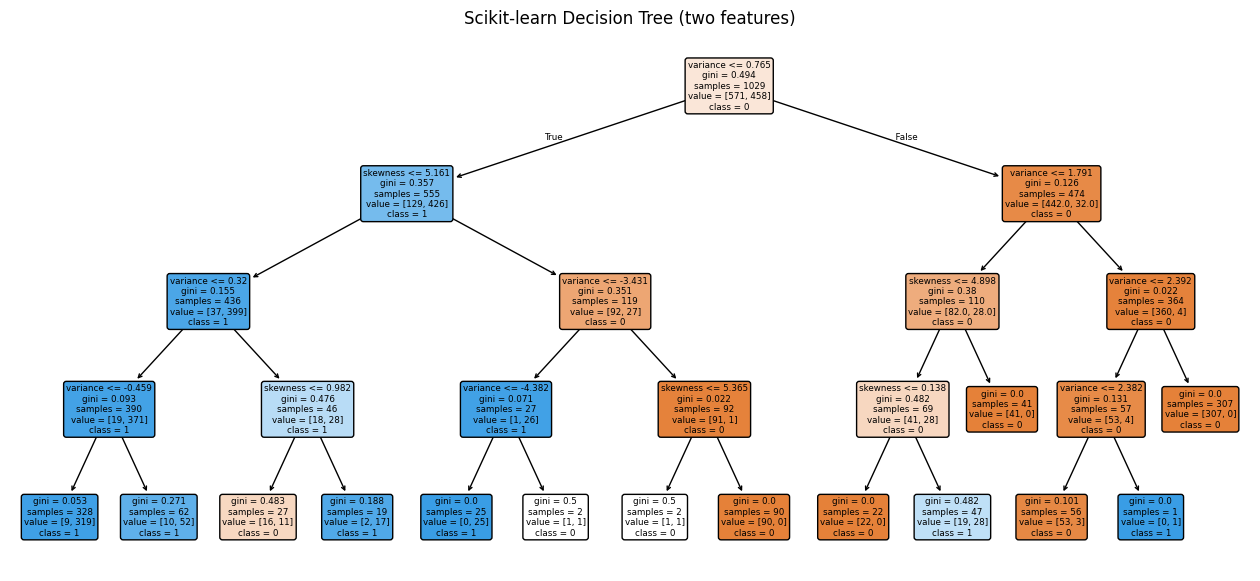

Manual tree split rules:
If variance <= 0.7651 (gain=0.2435)
 Left:
  If skewness <= 5.1608 (gain=0.1596)
   Left:
    If variance <= 0.3202 (gain=0.0222)
     Left:
      If variance <= -0.4586 (gain=0.0048)
       Left:
        Predict class = 1
       Right:
        Predict class = 1
     Right:
      If skewness <= 0.9819 (gain=0.1152)
       Left:
        Predict class = 0
       Right:
        Predict class = 1
   Right:
    If variance <= -3.4311 (gain=0.318)
     Left:
      If variance <= -4.3819 (gain=0.0343)
       Left:
        Predict class = 1
       Right:
        Predict class = 0
     Right:
      If skewness <= 5.3646 (gain=0.0106)
       Left:
        Predict class = 0
       Right:
        Predict class = 0
 Right:
  If variance <= 1.7907 (gain=0.0211)
   Left:
    If skewness <= 4.8979 (gain=0.077)
     Left:
      If skewness <= 0.1376 (gain=0.1542)
       Left:
        Predict class = 0
       Right:
        Predict class = 1
     Right:
      Predict class = 0
 

In [5]:
sk_tree_2d = DecisionTreeClassifier(max_depth=4, criterion="gini", random_state=42)
sk_tree_2d.fit(X2_train, y_train)
plt.figure(figsize=(16, 7))
plot_tree(sk_tree_2d, feature_names=["variance", "skewness"], class_names=["0", "1"],
          filled=True, rounded=True)
plt.title("Scikit-learn Decision Tree (two features)")
plt.show()
print("Manual tree split rules:")
print_tree(manual_tree)

### A3. Two-feature Decision Tree decision boundaries

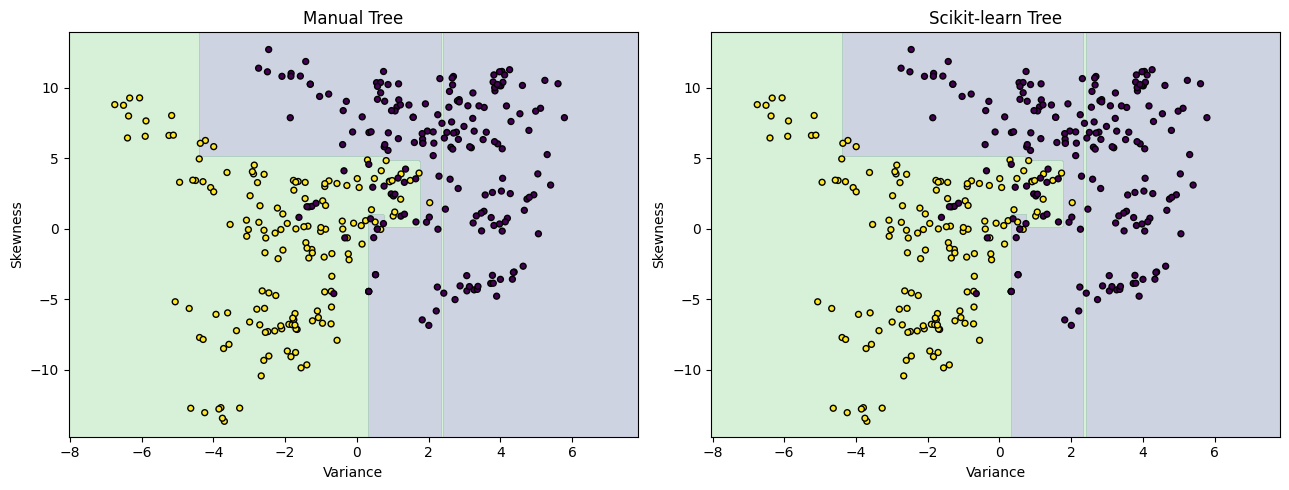

In [6]:
x_min, x_max = X2_train[:, 0].min()-1, X2_train[:, 0].max()+1
y_min, y_max = X2_train[:, 1].min()-1, X2_train[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 220), np.linspace(y_min, y_max, 220))
grid = np.c_[xx.ravel(), yy.ravel()]
manual_grid = predict_tree(grid, manual_tree).reshape(xx.shape)
sk_grid = sk_tree_2d.predict(grid).reshape(xx.shape)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].contourf(xx, yy, manual_grid, alpha=.25, levels=[-.5, .5, 1.5])
ax[0].scatter(X2_test[:, 0], X2_test[:, 1], c=y_test, edgecolors="k", s=18)
ax[0].set_title("Manual Tree"); ax[0].set_xlabel("Variance"); ax[0].set_ylabel("Skewness")
ax[1].contourf(xx, yy, sk_grid, alpha=.25, levels=[-.5, .5, 1.5])
ax[1].scatter(X2_test[:, 0], X2_test[:, 1], c=y_test, edgecolors="k", s=18)
ax[1].set_title("Scikit-learn Tree"); ax[1].set_xlabel("Variance"); ax[1].set_ylabel("Skewness")
plt.tight_layout(); plt.show()

# Part B — Linear Soft-Margin SVM from Scratch

The manual SVM uses \(f(x)=w^Tx+b\), labels \(-1,+1\), and hinge loss with L2 regularization. Training features are standardized using training-set means and standard deviations only. Subgradient descent updates weights and bias.

In [7]:
mean2, std2 = X2_train.mean(axis=0), X2_train.std(axis=0)
std2[std2 == 0] = 1
X2_train_scaled = (X2_train - mean2) / std2
X2_test_scaled = (X2_test - mean2) / std2
y_train_svm = np.where(y_train == 1, 1.0, -1.0)
y_test_svm = np.where(y_test == 1, 1.0, -1.0)

def train_svm(X, y, C=1.0, learning_rate=0.01, iterations=3000):
    w = np.zeros(X.shape[1])
    b = 0.0
    n = len(y)
    for _ in range(iterations):
        margin = y * (X @ w + b)
        bad = margin < 1
        dw = w - C * np.sum(y[bad, None] * X[bad], axis=0) / n
        db = -C * np.sum(y[bad]) / n
        w = w - learning_rate * dw
        b = b - learning_rate * db
    return w, b

def predict_svm(X, w, b):
    return np.where(X @ w + b >= 0, 1, -1)

start = time.perf_counter()
w_manual, b_manual = train_svm(X2_train_scaled, y_train_svm, C=1, learning_rate=.01, iterations=3000)
manual_svm_train_time = time.perf_counter() - start
start = time.perf_counter()
manual_svm_pred = predict_svm(X2_test_scaled, w_manual, b_manual)
manual_svm_predict_time = time.perf_counter() - start
print("Manual SVM accuracy:", round(accuracy_score(y_test_svm, manual_svm_pred), 4))
print("Weights:", w_manual, "Bias:", round(b_manual, 4))

Manual SVM accuracy: 0.8717
Weights: [-0.50021776 -0.25496919] Bias: -0.2887


### B1. Manual and Scikit-learn linear SVM boundaries, margins, and violations

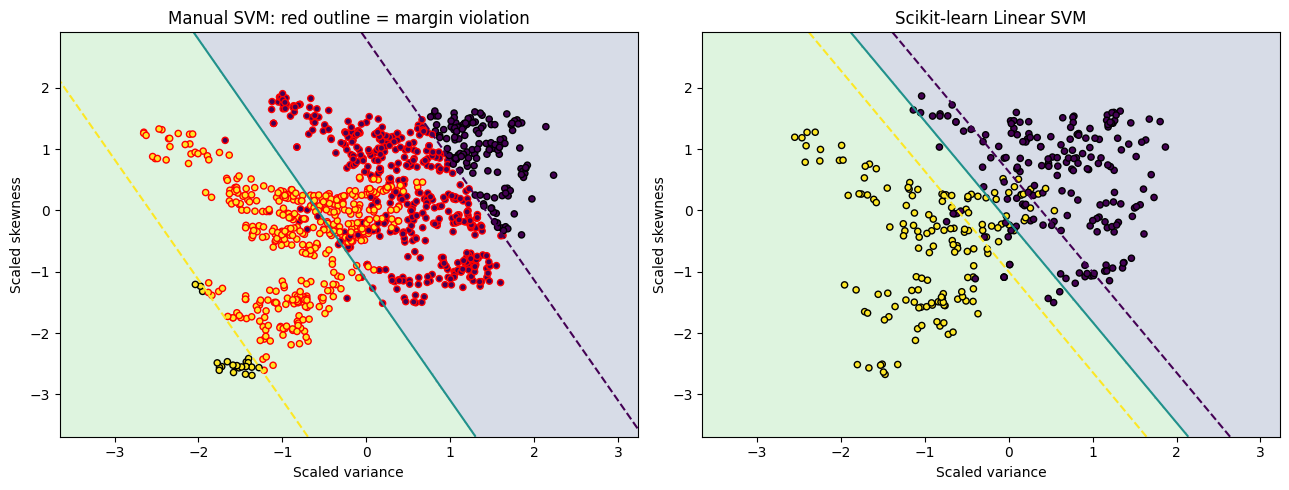

Manual accuracy: 0.8717201166180758
Scikit-learn linear SVM accuracy: 0.8892128279883382


In [8]:
sk_svm_2d = SVC(kernel="linear", C=1.0)
start = time.perf_counter()
sk_svm_2d.fit(X2_train_scaled, y_train_svm)
sk_svm_train_time = time.perf_counter() - start
start = time.perf_counter()
sk_svm_pred = sk_svm_2d.predict(X2_test_scaled)
sk_svm_predict_time = time.perf_counter() - start

x_min, x_max = X2_train_scaled[:, 0].min()-1, X2_train_scaled[:, 0].max()+1
y_min, y_max = X2_train_scaled[:, 1].min()-1, X2_train_scaled[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 220), np.linspace(y_min, y_max, 220))
grid = np.c_[xx.ravel(), yy.ravel()]
manual_scores = (grid @ w_manual + b_manual).reshape(xx.shape)
sk_scores = sk_svm_2d.decision_function(grid).reshape(xx.shape)
violating = y_train_svm * (X2_train_scaled @ w_manual + b_manual) < 1

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].contourf(xx, yy, manual_scores >= 0, alpha=.2)
ax[0].contour(xx, yy, manual_scores, levels=[-1, 0, 1], linestyles=["--", "-", "--"])
ax[0].scatter(X2_train_scaled[:, 0], X2_train_scaled[:, 1], c=y_train_svm,
              edgecolors=np.where(violating, "red", "black"), s=20)
ax[0].set_title("Manual SVM: red outline = margin violation")
ax[0].set_xlabel("Scaled variance"); ax[0].set_ylabel("Scaled skewness")
ax[1].contourf(xx, yy, sk_scores >= 0, alpha=.2)
ax[1].contour(xx, yy, sk_scores, levels=[-1, 0, 1], linestyles=["--", "-", "--"])
ax[1].scatter(X2_test_scaled[:, 0], X2_test_scaled[:, 1], c=y_test_svm, edgecolors="black", s=20)
ax[1].set_title("Scikit-learn Linear SVM")
ax[1].set_xlabel("Scaled variance"); ax[1].set_ylabel("Scaled skewness")
plt.tight_layout(); plt.show()
print("Manual accuracy:", accuracy_score(y_test_svm, manual_svm_pred))
print("Scikit-learn linear SVM accuracy:", accuracy_score(y_test_svm, sk_svm_pred))

### B2. Regularization C, learning rate, and iteration experiments

In [9]:
svm_rows = []
for C in [.1, 1, 10]:
    for lr, iterations in [(.001, 3000), (.01, 3000), (.01, 6000)]:
        start = time.perf_counter()
        w, b = train_svm(X2_train_scaled, y_train_svm, C=C, learning_rate=lr, iterations=iterations)
        train_time = time.perf_counter() - start
        pred = predict_svm(X2_test_scaled, w, b)
        svm_rows.append([C, lr, iterations, accuracy_score(y_test_svm, pred), train_time])
display(pd.DataFrame(svm_rows, columns=["C", "Learning rate", "Iterations", "Accuracy", "Train time (s)"]).round(4))

,C,Learning rate,Iterations,Accuracy,Train time (s)
0,0.1,0.001,3000,0.8805,0.3124
1,0.1,0.010,3000,0.5569,0.2439
2,0.1,0.010,6000,0.5569,0.4270
3,1.0,0.001,3000,0.8863,0.1951
4,1.0,0.010,3000,0.8717,0.2388
5,1.0,0.010,6000,0.8717,0.4571
6,10.0,0.001,3000,0.8921,0.1618
7,10.0,0.010,3000,0.8921,0.1493
8,10.0,0.010,6000,0.8921,0.3291


# Part C — Kernel SVM and Nonlinear Boundaries

A synthetic `make_moons` dataset shows why nonlinear kernels can help. Linear, polynomial, and RBF SVMs are trained on the same split.

,Kernel,Accuracy,F1-score,Train time (s),Predict time (s)
0,Linear,0.848,0.8430,0.0047,0.0010
1,Polynomial,0.840,0.8361,0.0053,0.0013
2,RBF,0.976,0.9752,0.0038,0.0027


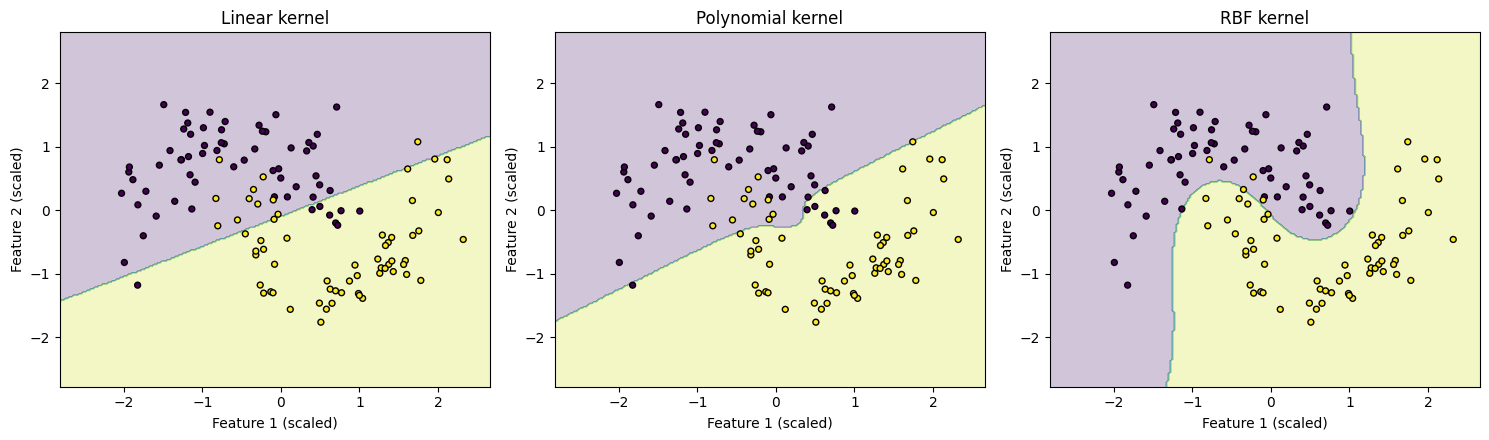

In [10]:
Xm, ym = make_moons(n_samples=500, noise=.22, random_state=42)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    Xm, ym, test_size=.25, random_state=42, stratify=ym
)
moon_scaler = StandardScaler()
Xm_train = moon_scaler.fit_transform(Xm_train)
Xm_test = moon_scaler.transform(Xm_test)

kernels = {
    "Linear": SVC(kernel="linear", C=1),
    "Polynomial": SVC(kernel="poly", degree=3, C=1),
    "RBF": SVC(kernel="rbf", C=1, gamma="scale")
}
kernel_rows = []
for name, model in kernels.items():
    start = time.perf_counter(); model.fit(Xm_train, ym_train); train_time = time.perf_counter()-start
    start = time.perf_counter(); pred = model.predict(Xm_test); pred_time = time.perf_counter()-start
    kernel_rows.append([name, accuracy_score(ym_test, pred), f1_score(ym_test, pred), train_time, pred_time])
display(pd.DataFrame(kernel_rows, columns=["Kernel", "Accuracy", "F1-score", "Train time (s)", "Predict time (s)"]).round(4))

x_min, x_max = Xm_train[:, 0].min()-.5, Xm_train[:, 0].max()+.5
y_min, y_max = Xm_train[:, 1].min()-.5, Xm_train[:, 1].max()+.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 220), np.linspace(y_min, y_max, 220))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for axis, (name, model) in zip(ax, kernels.items()):
    boundary = model.predict(grid).reshape(xx.shape)
    axis.contourf(xx, yy, boundary, alpha=.25)
    axis.scatter(Xm_test[:, 0], Xm_test[:, 1], c=ym_test, edgecolors="k", s=18)
    axis.set_title(name + " kernel")
    axis.set_xlabel("Feature 1 (scaled)"); axis.set_ylabel("Feature 2 (scaled)")
plt.tight_layout(); plt.show()

**Observation:** A linear SVM has a straight decision boundary. Polynomial and RBF kernels can form curved boundaries, which may better capture the curved structure of the moons data. More flexible boundaries can also overfit.

# Part D — Final Comparison Using All Four Features

All models below use the same Banknote train-test split and all four original features. Decision Trees use unscaled features; manual and Scikit-learn SVMs use standardized features, with scaling statistics computed only from the training set.

In [11]:
# Manual Decision Tree (four features)
start = time.perf_counter()
manual_tree4 = build_tree(X_train, y_train, max_depth=5, criterion="gini")
manual_tree4_train = time.perf_counter()-start
start = time.perf_counter()
pred_tree_manual = predict_tree(X_test, manual_tree4)
manual_tree4_pred = time.perf_counter()-start

# Scikit-learn Decision Tree (four features)
sk_tree4 = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42)
start = time.perf_counter(); sk_tree4.fit(X_train, y_train); sk_tree4_train = time.perf_counter()-start
start = time.perf_counter(); pred_tree_sk = sk_tree4.predict(X_test); sk_tree4_pred = time.perf_counter()-start

# Scale all four features from training statistics only
mean4, std4 = X_train.mean(axis=0), X_train.std(axis=0)
std4[std4 == 0] = 1
X_train4 = (X_train-mean4)/std4
X_test4 = (X_test-mean4)/std4
y_train4 = np.where(y_train == 1, 1.0, -1.0)
y_test4 = np.where(y_test == 1, 1.0, -1.0)

# Manual linear SVM
start = time.perf_counter()
w4, b4 = train_svm(X_train4, y_train4, C=1, learning_rate=.01, iterations=5000)
manual_svm4_train = time.perf_counter()-start
start = time.perf_counter()
pred_svm_manual = np.where(predict_svm(X_test4, w4, b4) == 1, 1, 0)
manual_svm4_pred = time.perf_counter()-start

# Scikit-learn linear SVM
sk_linear4 = SVC(kernel="linear", C=1)
start = time.perf_counter(); sk_linear4.fit(X_train4, y_train4); sk_linear4_train = time.perf_counter()-start
start = time.perf_counter(); pred_linear = np.where(sk_linear4.predict(X_test4) == 1, 1, 0); sk_linear4_pred = time.perf_counter()-start

# Scikit-learn RBF SVM
sk_rbf4 = SVC(kernel="rbf", C=1, gamma="scale")
start = time.perf_counter(); sk_rbf4.fit(X_train4, y_train); sk_rbf4_train = time.perf_counter()-start
start = time.perf_counter(); pred_rbf = sk_rbf4.predict(X_test4); sk_rbf4_pred = time.perf_counter()-start

model_names = ["Manual Decision Tree", "Scikit-learn Decision Tree", "Manual Linear SVM",
               "Scikit-learn Linear SVM", "Scikit-learn RBF SVM"]
predictions = [pred_tree_manual, pred_tree_sk, pred_svm_manual, pred_linear, pred_rbf]
train_times = [manual_tree4_train, sk_tree4_train, manual_svm4_train, sk_linear4_train, sk_rbf4_train]
predict_times = [manual_tree4_pred, sk_tree4_pred, manual_svm4_pred, sk_linear4_pred, sk_rbf4_pred]

rows = []
for i in range(len(model_names)):
    rows.append([
        model_names[i],
        accuracy_score(y_test, predictions[i]),
        precision_score(y_test, predictions[i], zero_division=0),
        recall_score(y_test, predictions[i], zero_division=0),
        f1_score(y_test, predictions[i], zero_division=0),
        train_times[i], predict_times[i]
    ])
final_results = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1-score",
                                            "Training time (s)", "Prediction time (s)"])
display(final_results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,Training time (s),Prediction time (s)
0,Manual Decision Tree,0.9854,0.9742,0.9934,0.9837,1.3142,0.0005
1,Scikit-learn Decision Tree,0.9854,0.9742,0.9934,0.9837,0.0034,0.0005
2,Manual Linear SVM,0.8921,0.9528,0.7961,0.8674,0.3832,0.0001
3,Scikit-learn Linear SVM,0.9767,0.9500,1.0000,0.9744,0.0046,0.0007
4,Scikit-learn RBF SVM,1.0000,1.0000,1.0000,1.0000,0.0043,0.0017


## Final observations and conclusion

- **Interpretability:** Decision Trees provide readable feature-threshold rules; SVMs are generally less interpretable.
- **Overfitting:** Deeper trees and highly flexible kernels can fit complex patterns but may overfit.
- **Scaling:** SVMs are sensitive to feature scale; scaling must be fitted on training data only. Trees usually do not require scaling.
- **Regularization:** SVM parameter `C` controls the trade-off between margin size and training errors.
- **Complexity:** The manual algorithms make the learning process visible, while Scikit-learn implementations are optimized and may run faster.
- Use the final comparison table above to discuss which model performed best on this particular split. Timing varies by machine and execution environment.